# DSCI 552 Homework 5

-Name: Shiyi Fan  
-GitHub Username: 1111v1y\
-USC ID: 5554653109

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import _tree
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

## 1. Decision Trees as Interpretable Models
### 1.(a)

In [2]:
data = pd.read_csv(
    "../data/diagnosis.data",
    sep="\t",
    header=None,
    encoding="utf-16"
)
data.columns = [
    "Temperature",
    "Nausea",
    "Lumbar_pain",
    "Urine_pushing",
    "Micturition_pains",
    "Burning_urethra",
    "Inflammation",
    "Nephritis"
]

data["Temperature"] = data["Temperature"].str.replace(",", ".").astype(float)

### 1.(b)

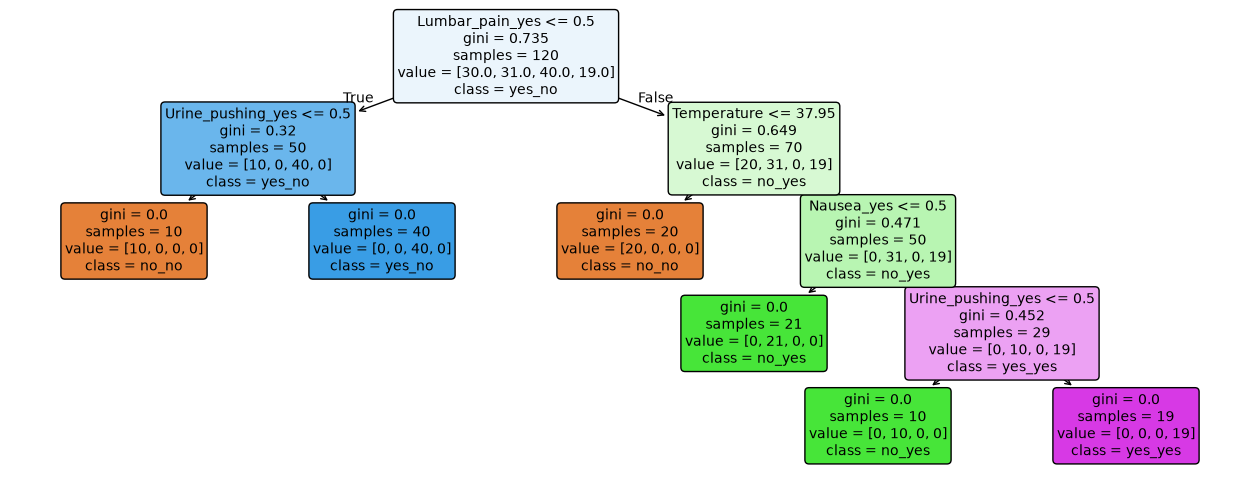

In [3]:
X = data.iloc[:, :6]
y = data["Inflammation"] + "_" + data["Nephritis"]
X = pd.get_dummies(X, drop_first = True)
treemodel = DecisionTreeClassifier(random_state = 1)
treemodel.fit(X, y)

plt.figure(figsize = (16, 6))
plot_tree(
    treemodel,
    feature_names = X.columns,
    class_names = treemodel.classes_,
    filled = True,
    rounded = True
)
plt.show()

### 1.(c)

In [4]:
def print_rules(model, feature_names):
    tree = model.tree_
    def traverse(node, conditions):
        if tree.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[node]]
            if feature.endswith("_yes"):
                name = feature[:-4].replace("_", " ")
                traverse(tree.children_left[node], conditions + [f"{name} = no"])
                traverse(tree.children_right[node], conditions + [f"{name} = yes"])
            else:
                threshold = tree.threshold[node]
                traverse(tree.children_left[node], conditions + [f"{feature} <= {threshold:.2f}"])
                traverse(tree.children_right[node], conditions + [f"{feature} > {threshold:.2f}"])
        else:
            label = model.classes_[tree.value[node][0].argmax()]
            inflammation, nephritis = label.split("_")
            print(
                "IF " + " AND ".join(conditions) +
                f" THEN Inflammation = {inflammation} AND Nephritis = {nephritis}"
            )
    traverse(0, [])

print_rules(treemodel, list(X.columns))

IF Lumbar pain = no AND Urine pushing = no THEN Inflammation = no AND Nephritis = no
IF Lumbar pain = no AND Urine pushing = yes THEN Inflammation = yes AND Nephritis = no
IF Lumbar pain = yes AND Temperature <= 37.95 THEN Inflammation = no AND Nephritis = no
IF Lumbar pain = yes AND Temperature > 37.95 AND Nausea = no THEN Inflammation = no AND Nephritis = yes
IF Lumbar pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine pushing = no THEN Inflammation = no AND Nephritis = yes
IF Lumbar pain = yes AND Temperature > 37.95 AND Nausea = yes AND Urine pushing = yes THEN Inflammation = yes AND Nephritis = yes


### 1.(d)

In [5]:
path = treemodel.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 1)
scores = []
for alpha in alphas:
    model = DecisionTreeClassifier(random_state = 42, ccp_alpha = alpha)
    score = cross_val_score(model, X, y, cv = cv).mean()
    scores.append(score)
bestalpha = alphas[np.argmax(scores)]
pruned_tree = DecisionTreeClassifier(
    random_state = 1,
    ccp_alpha = bestalpha
)
pruned_tree.fit(X, y)

print("Best ccp_alpha:", bestalpha)
print("Cross-validation accuracy:", max(scores))
print("Number of leaves:", pruned_tree.get_n_leaves())

Best ccp_alpha: 0.0
Cross-validation accuracy: 0.975
Number of leaves: 6


## 2. The LASSO and Boosting for Regression
### 2.(a)

In [6]:
names = []
with open("../data/communities.names", encoding = "latin1") as file:
    for line in file:
        if line.startswith("@attribute"):
            names.append(line.split()[1])
crime = pd.read_csv(
    "../data/communities.data",
    header = None,
    names = names,
    na_values = "?"
)
train = crime.iloc[:1495].copy()
test = crime.iloc[1495:].copy()

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (1495, 128)
Test set: (499, 128)


### 2.(b)

In [7]:
target = "ViolentCrimesPerPop"
nonpredictive = ["state", "county", "community", "communityname", "fold"]
X_train = train.drop(columns=nonpredictive + [target])
y_train = train[target]
X_test = test.drop(columns=nonpredictive + [target])
y_test = test[target]
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns = X_train.columns,
    index = X_train.index
)
X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns = X_test.columns,
    index = X_test.index
)

print("Number of features:", X_train.shape[1])
print("Missing values in training set:", X_train.isna().sum().sum())
print("Missing values in test set:", X_test.isna().sum().sum())

Number of features: 122
Missing values in training set: 0
Missing values in test set: 0


### 2.(c)

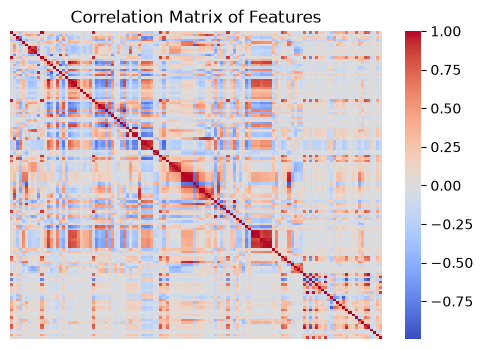

In [8]:
plt.figure(figsize = (6, 4))
sns.heatmap(
    X_train.corr(),
    cmap = "coolwarm",
    center = 0,
    xticklabels = False,
    yticklabels = False
)

plt.title("Correlation Matrix of Features")
plt.show()

### 2.(d)

In [9]:
cv_values = X_train.std() / X_train.mean()

cv_table = cv_values.sort_values(ascending = False).to_frame(name = "CV")
cv_table

,CV
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
...,...
NumKindsDrugsSeiz,0.141021
RacialMatchCommPol,0.129652
PctPolicWhite,0.118727
LemasPctPolicOnPatr,0.112032


### 2.(e)

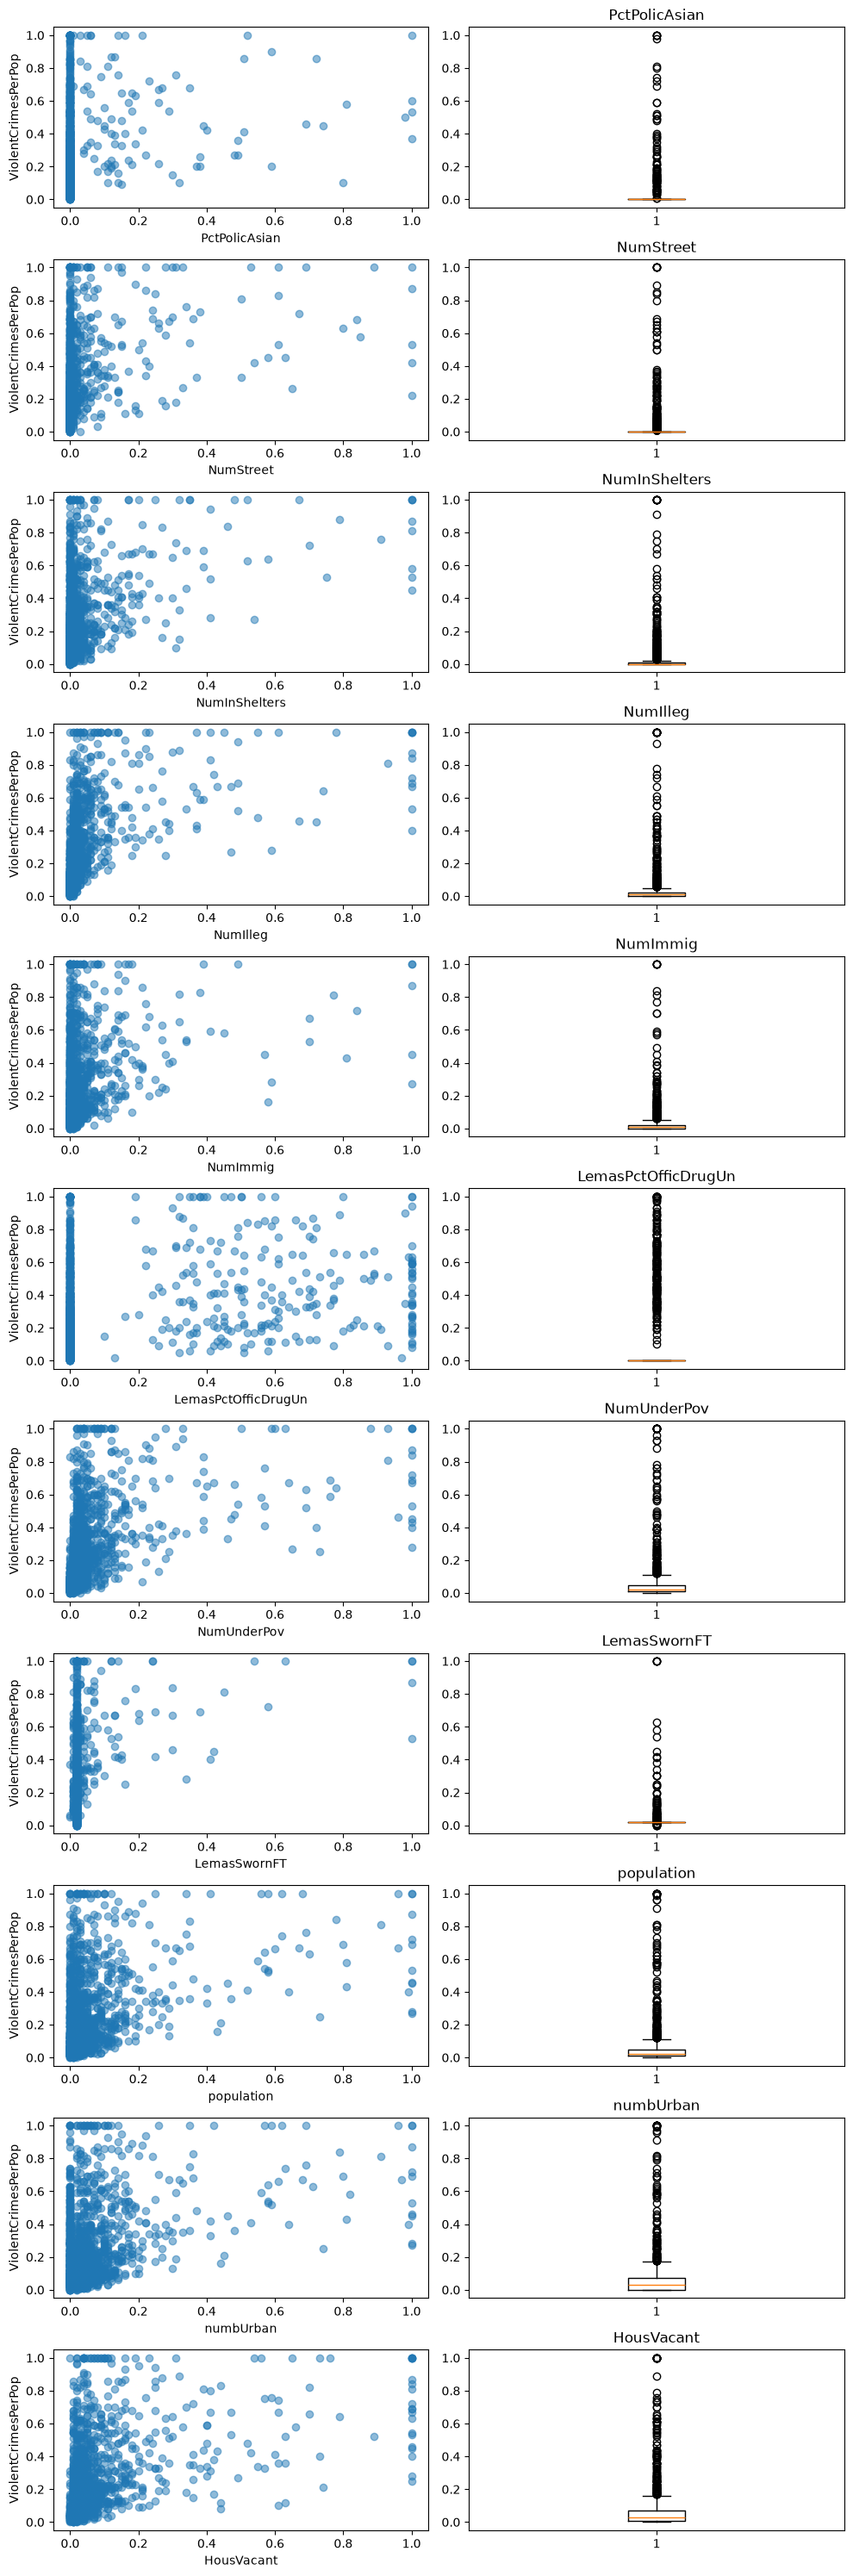

In [10]:
top_features = cv_table.head(11).index
fig, axes = plt.subplots(11, 2, figsize = (10, 30))
for i, feature in enumerate(top_features):
    axes[i, 0].scatter(X_train[feature], y_train, alpha = 0.5)
    axes[i, 0].set_xlabel(feature)
    axes[i, 0].set_ylabel("ViolentCrimesPerPop")
    axes[i, 1].boxplot(X_train[feature])
    axes[i, 1].set_title(feature)

plt.tight_layout()
plt.show()

##### -We cannot determine the statistical significance of these features only based on scatter plots

### 2.(f)

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
linearmodel = LinearRegression()
linearmodel.fit(X_train, y_train)
linearpredictions = linearmodel.predict(X_test)
lineartest_error = mean_squared_error(y_test, linearpredictions)

print("Linear regression test MSE:", lineartest_error)

Linear regression test MSE: 0.01796621542606734


### 2.(g)

In [12]:
from sklearn.linear_model import RidgeCV
alphas = np.logspace(-4, 4, 100)
ridgemodel = RidgeCV(
    alphas = alphas,
    cv = 5,
    scoring = "neg_mean_squared_error"
)
ridgemodel.fit(X_train, y_train)
ridgepredictions = ridgemodel.predict(X_test)
ridgetest_error = mean_squared_error(y_test, ridgepredictions)

print("Best lambda:", ridgemodel.alpha_)
print("Ridge regression test MSE:", ridgetest_error)

Best lambda: 2.310129700083163
Ridge regression test MSE: 0.01751624930256487


### 2.(h)

In [13]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
alphas = np.logspace(-4, 0, 100)
lassomodel = LassoCV(
    alphas = alphas,
    cv = 5,
    max_iter = 100000,
    random_state = 1
)
lassomodel.fit(X_train, y_train)
lassopredictions = lassomodel.predict(X_test)
lassotest_error = mean_squared_error(y_test, lassopredictions)
lassoselected = X_train.columns[lassomodel.coef_ != 0].tolist()
scaler = StandardScaler()
X_train_stan = scaler.fit_transform(X_train)
X_test_stan = scaler.transform(X_test)
lassostan_model = LassoCV(
    alphas = alphas,
    cv = 5,
    max_iter = 100000,
    random_state = 1
)
lassostan_model.fit(X_train_stan, y_train)
lassostan_predictions = lassostan_model.predict(X_test_stan)
lassostan_test_error = mean_squared_error(
    y_test,
    lassostan_predictions
)
lassostan_selected = X_train.columns[
    lassostan_model.coef_ != 0
].tolist()

print("Without standardization")
print("Best lambda:", lassomodel.alpha_)
print("Test MSE:", lassotest_error)
print("Selected variables:", lassoselected)
print("\nWith standardization")
print("Best lambda:", lassostan_model.alpha_)
print("Test MSE:", lassostan_test_error)
print("Selected variables:", lassostan_selected)

Without standardization
Best lambda: 0.00013219411484660288
Test MSE: 0.017605994924612504
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', '

##### -test MSE without standardization: 0.017606
##### -the test MSE with standardization: 0.017679

### 2.(i)

In [14]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
pcr = Pipeline([
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])
param_grid = {
    "pca__n_components": range(1, X_train.shape[1] + 1)
}
pcr_cv = GridSearchCV(
    pcr,
    param_grid,
    cv = 5,
    scoring = "neg_mean_squared_error"
)
pcr_cv.fit(X_train, y_train)
pcr_predictions = pcr_cv.predict(X_test)
pcr_test_error = mean_squared_error(y_test, pcr_predictions)

print("Best number of components (M):", pcr_cv.best_params_["pca__n_components"])
print("PCR test MSE:", pcr_test_error)

Best number of components (M): 96
PCR test MSE: 0.018339861732081932


### 2.(j)

In [15]:
from xgboost import XGBRegressor
xgbmodel = XGBRegressor(
    objective = "reg:squarederror",
    n_estimators = 300,
    learning_rate = 0.05,
    max_depth = 3,
    random_state = 1,
    n_jobs = 1
)
alpha_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}
xgbcv = GridSearchCV(
    xgbmodel,
    param_grid = alpha_grid,
    cv = 5,
    scoring = "neg_mean_squared_error",
    n_jobs = -1
)
xgbcv.fit(X_train, y_train)

print("Best alpha:", xgbcv.best_params_["reg_alpha"])

Best alpha: 0.01
